<a href="https://colab.research.google.com/github/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting/blob/main/Chapter03_Zero_Shot_Forecasting/06_zero_shot_moirai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 06 · Zero-shot forecasting with the Moirai family

*Hands-On Open-Source Foundation Models for Time Series Forecasting*, Chapter 3: Zero-Shot Forecasting in Practice

This notebook runs Salesforce's Moirai-1.1, Moirai-MoE and Moirai-2.0 zero-shot: the models forecast our series straight away, without any training on
our data. Each model forecasts every dataset, every horizon (7, 14, 30, 60 and 90 days (D1, D2) and 3, 6, 9, 12 and 24 months (D3, D4)) and every rolling window fixed in
Notebook 04.

For each model you will find a figure of its architecture, a plain description of how it works and what is new
about it, what it costs to run, and which covariates it can read without fine-tuning. The figures were checked
against each model's paper, its released configuration and the network as loaded.

#### Why these models share a notebook

They install into the same Python environment (`requirements/env-moirai.txt`). Foundation-model libraries pin
different versions of `torch`, `numpy` and `transformers`, and these often clash, so the chapter groups the models
by the environment they need rather than by the company that made them.

The datasets are D1 (daily Central England temperature), D2 (D1 with 12 covariates), D3 (five monthly metal prices) and D4 (D3 with three global drivers, each known up to the forecast origin). The bonus datasets B1 and B2 have their own notebook: [bonus/B06_zero_shot_moirai.ipynb](bonus/B06_zero_shot_moirai.ipynb).

**What you will learn**

- what is inside each model, drawn layer by layer in one consistent style, with the maths of each layer explained
- which models can use past-only and known-future covariates without fine-tuning, and how they do it
- how the models' point forecasts compare across datasets and horizons, by MASE and by RMSE, and what they cost
  to run on a CPU
- how the forecasts look against the actual values at every horizon

| Environment and compute | |
|---|---|
| Python | 3.12 (tested); see *How to run* for Colab |
| Packages | [`requirements/env-moirai.txt`](requirements/env-moirai.txt) (pinned) |
| Hardware | CPU only; a GPU is used automatically if present |
| Network | downloads the checkpoints from Hugging Face on first use |
| Run time, quick check (default) | about 7.5 s of forecasting on 4 CPU cores (Colab's free tier has 2 cores: allow about twice as long) |
| Run time, `FULL_RUN = True` | about 42 min of forecasting with one CPU thread, while other notebooks shared the machine |
| Peak memory | 2.6 GB above the kernel's baseline (largest single call) |

**How to run this notebook**

- **Google Colab:** this notebook needs Python 3.12, so first choose *Runtime > Change runtime type* and pick a *Runtime version* with Python 3.12 (such as 2026.07). Then choose *Runtime > Run all*. The first code cell fetches this chapter's folder and installs `requirements/env-moirai.txt`
  with uv (a few minutes the first time). If it says it is restarting the session, wait, then choose *Runtime > Run all*
  again. To use your own copy on Google Drive, set `DRIVE_COPY` in that cell to the folder's path. A GPU runtime
  is not needed; if you pick one, the models use it.
- **Your own computer (Cursor, VS Code or Jupyter):** create the environment once with
  `uv venv .venv-moirai -p 3.12 && uv pip install -p .venv-moirai -r requirements/env-moirai.txt`
  (or `python3.12 -m venv .venv-moirai` and `pip install -r ...`), open this folder, choose the `.venv-moirai` kernel
  and run all cells.

In [1]:
# Setup: find this chapter's folder (on Colab: fetch it and install this notebook's environment)
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules


def is_chapter(d):
    return (Path(d) / "src" / "ch03_dataprep" / "__init__.py").is_file()


if IN_COLAB:  # get this chapter's folder and install this notebook's environment
    if sys.version_info >= (3, 13):  # env-moirai pins packages that have no builds for newer Python
        raise RuntimeError(f"This notebook needs Python 3.12, and this Colab runtime has Python {sys.version.split()[0]}. "
                           "Choose Runtime > Change runtime type, pick a Runtime version with Python 3.12 (such as 2026.07), "
                           "then choose Runtime > Run all again.")
    import shutil

    CHAPTER = "Chapter03_Zero_Shot_Forecasting"   # this chapter's folder in the book's repository
    DRIVE_COPY = ""   # optional: path of your own copy of this folder on Google Drive (skips GitHub)
    BOOK = Path("/content/book")

    def chapter_dir():  # this chapter's folder under /content/book, or None until it is there
        return next((d for d in (BOOK / CHAPTER, BOOK) if is_chapter(d)), None)

    def find_in_drive(top="/content/drive/MyDrive", depth=6):  # the copies of CHAPTER, shallowest first
        level = [top]
        for _ in range(depth):
            subdirs = []
            for d in level:
                try:
                    subdirs += [e.path for e in os.scandir(d) if e.is_dir() and not e.name.startswith(".")]
                except OSError:
                    pass
            hits = [d for d in subdirs if Path(d).name == CHAPTER and is_chapter(d)]
            if hits:
                return hits
            level = subdirs
        return []

    def local_only(d, names):  # what not to copy from Drive: local environments, caches, downloaded data
        return [n for n in names if n.startswith(".venv") or n == "__pycache__" or (d.endswith("/data") and n == "raw")]

    if chapter_dir() is None and not DRIVE_COPY:    # 1) clone the book's repository from GitHub
        shutil.rmtree(BOOK, ignore_errors=True)
        !GIT_TERMINAL_PROMPT=0 git clone -q --depth 1 https://github.com/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting /content/book
    if chapter_dir() is None:                       # 2) not on GitHub (yet): copy it from your Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        if not DRIVE_COPY:
            print(f"{CHAPTER} is not on GitHub: searching My Drive for it (set DRIVE_COPY above to skip this)")
            hits = find_in_drive()
            if len(hits) > 1:
                raise FileExistsError(f"several copies of {CHAPTER} in My Drive: {hits}. Set DRIVE_COPY to one.")
            DRIVE_COPY = hits[0] if hits else ""
        if DRIVE_COPY and not is_chapter(DRIVE_COPY):
            raise FileNotFoundError(f"DRIVE_COPY = {DRIVE_COPY!r} is not this chapter's folder (no src/ch03_dataprep)")
        if DRIVE_COPY:
            print(f"copying {DRIVE_COPY} to {BOOK / CHAPTER} ...")
            shutil.rmtree(BOOK, ignore_errors=True)
            shutil.copytree(DRIVE_COPY, BOOK / "partial-copy", ignore=local_only)
            (BOOK / "partial-copy").rename(BOOK / CHAPTER)    # only a finished copy gets the chapter's name
            print(f"copied {sum(len(files) for _, _, files in os.walk(BOOK / CHAPTER)):,} files")
    if chapter_dir() is None:
        raise FileNotFoundError(f"{CHAPTER} is not in the book's GitHub repository or in your Google Drive. "
                                "Upload the folder to Drive, or set DRIVE_COPY above to its path there.")
    os.chdir(chapter_dir())
    import importlib.metadata as md

    def key(name):  # package installers treat huggingface_hub and huggingface-hub as one package
        return name.lower().replace("_", "-").replace(".", "-")

    def versions():  # the version of every installed package, as Python finds it (first copy on sys.path)
        found = {}
        for d in md.distributions():
            found.setdefault(key(d.metadata["Name"]), d.version)
        return found

    before = versions()
    # Install with uv: it downloads and installs packages in parallel, several times faster than pip. Colab comes
    # with uv (installed here if not). The settings point uv at Colab's own Python (Colab has no virtual environment)
    # and drop install constraints that Colab may have left over from building its image. Each uv line falls back
    # to pip if uv fails.
    if shutil.which("uv") is None:
        %pip install -q uv
    for name in ("UV_CONSTRAINT", "UV_BUILD_CONSTRAINT", "UV_PRERELEASE"):
        os.environ.pop(name, None)
    os.environ.update(UV_PYTHON=sys.executable, UV_SYSTEM_PYTHON="1", UV_BREAK_SYSTEM_PACKAGES="1")
    # keep Colab's own torch (with CUDA) and Jupyter; install everything else this notebook needs
    !grep -vE "^(torch|jupyter|ipykernel|nbclient|nbformat|pytest|nbval|ruff)==" requirements/env-moirai.txt > /tmp/requirements-colab.txt
    !uv pip install -q -r /tmp/requirements-colab.txt || {sys.executable} -m pip install -q -r /tmp/requirements-colab.txt
    # stop here if neither uv nor pip could install everything; the error message is above
    try:
        from packaging.version import Version
    except ImportError:
        Version = str
    missing = []
    for line in open("/tmp/requirements-colab.txt"):
        name, _, pin = line.split("#")[0].strip().partition("==")
        if not pin:
            continue
        try:
            installed = md.version(name.split("[")[0])
        except md.PackageNotFoundError:
            installed = None
        if installed is None or Version(installed) != Version(pin):
            missing.append(f"{name}=={pin}")
    if missing:
        raise RuntimeError(f"Could not install {', '.join(missing)}; scroll up for its error. If it was a network error, "
                           "run this cell again. If uv or pip tried to build a package from source, this runtime's Python is "
                           "too new for this notebook: see the How to run section at the top.")
    # Colab comes with torchvision, torchaudio, torchcodec and transformers, and torchmetrics imports some of them
    # whenever they are installed. If the install changed a package they depend on (some environments replace torch or
    # huggingface-hub), they no longer load. This notebook does not need them, so remove those that broke.
    try:
        from packaging.requirements import Requirement
    except ImportError:  # Colab has packaging; pip always carries its own copy
        from pip._vendor.packaging.requirements import Requirement

    now = versions()
    changed = {name for name, version in now.items() if before.get(name) != version}
    if "torch" in changed:
        # This notebook needs another torch than Colab's (Notebook 06: 2.4.1). Replacing torch can leave some of the
        # old torch's files behind, and Python then loads them ("cannot import name ... from torch.onnx"). Reinstall
        # it into clean folders (uv takes it from its cache, so nothing downloads twice).
        print(f"Replacing Colab's torch {before.get('torch')} with {now['torch']}: reinstalling it into clean folders ...")
        torch_pin = now["torch"]
        site = Path(md.distribution("torch").locate_file(""))
        folders = [site / m for m, names in md.packages_distributions().items()
                   if "torch" in names and m.isidentifier() and (site / m).is_dir()]
        !uv pip uninstall -q torch || {sys.executable} -m pip uninstall -q -y torch
        for folder in folders:
            shutil.rmtree(folder, ignore_errors=True)
        !uv pip install -q torch=={torch_pin} || {sys.executable} -m pip install -q torch=={torch_pin}
        now = versions()

    def requirements(dist):  # the requirements of an installed package that apply here
        found = []
        for line in md.requires(dist) or []:
            try:
                r = Requirement(line)
                if r.marker is None or r.marker.evaluate({"extra": ""}):
                    found.append(r)
            except Exception:  # a line this version of packaging cannot read
                pass
        return found

    def broken(dist):  # Colab's copy of dist, and the install changed something it needs
        if dist not in now or dist in changed:
            return False  # not installed, or installed by this notebook
        if "torch" in changed:
            return True   # Colab built and tested it with its own torch
        return any(key(r.name) in changed and not r.specifier.contains(now[key(r.name)], prereleases=True)
                   for r in requirements(dist))

    misfits = [d for d in ("torchvision", "torchaudio", "torchcodec", "transformers") if broken(d)]
    if misfits:
        print(f"Removing unused packages that this install broke: {', '.join(misfits)}")
        !uv pip uninstall -q {" ".join(misfits)} || {sys.executable} -m pip uninstall -q -y {" ".join(misfits)}
    # Colab imports some packages (numpy, pandas, torch, ...) before this cell finishes. If the install replaced one
    # of them, Python keeps the old version in memory and mixes it with the new files on disk (errors such as
    # "cannot import name ... from torch.onnx"), so restart once to load the new version.
    after = versions()
    stale = sorted(m for m, names in md.packages_distributions().items() if m in sys.modules
                   and any(before.get(key(n), after.get(key(n))) != after.get(key(n)) for n in names))
    for m in ("torch", "numpy", "pandas", "scipy"):  # also catches a session that was not restarted after an earlier run
        loaded = str(getattr(sys.modules.get(m), "__version__", ""))
        if loaded and m not in stale and loaded.split("+")[0] != after.get(m, loaded).split("+")[0]:
            stale.append(m)
    restarted_from = Path("/tmp/ch03_restart_pid")   # the session this cell last asked to restart
    if stale and restarted_from.is_file() and restarted_from.read_text() == str(os.getpid()):
        raise SystemExit(f"The session has not restarted and still has the old {', '.join(stale)} in memory. "
                         "Choose Runtime > Restart session, then Runtime > Run all.")
    if stale:
        restarted_from.write_text(str(os.getpid()))
        print(f"The install updated {', '.join(stale)}, which Colab had already loaded: restarting the session.")
        from IPython import get_ipython
        kernel = getattr(get_ipython(), "kernel", None)
        if kernel is not None:
            kernel.do_shutdown(True)
        raise SystemExit("When the session has restarted, choose Runtime > Run all again; the first cell then finishes quickly. "
                         "If it has not restarted after a few seconds, choose Runtime > Restart session, then Runtime > Run all.")
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if is_chapter(p))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)
DATA, RESULTS, INPUT = ROOT / "data", ROOT / "results", ROOT / "input_timeseries"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"chapter folder: {ROOT}  |  Python {sys.version.split()[0]}  |  Colab: {IN_COLAB}  |  device: {DEVICE}")

chapter folder: /home/user/fresh/repo/Chapter03_Zero_Shot_Forecasting  |  Python 3.12.13  |  Colab: False  |  device: cpu


#### Quick check or full run

With `FULL_RUN = False`, the default, each model makes a quick check: it forecasts the fixed-origin window at the
two shortest horizons of every dataset. That is enough to show that the model installs and runs on your machine.
The analysis then reads the stored results of the full runs (every horizon and every rolling window) from
`results/forecasts/`. Set `FULL_RUN = True` to recompute those full results yourself.

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from ch03_dataprep.plotting import set_style
from ch03_zeroshot.architectures import figure
from ch03_zeroshot.capabilities import capability_table
from ch03_zeroshot.data import load_frame
from ch03_zeroshot.models import get_model
from ch03_zeroshot.report import (cost_table, forecast_gallery, gain_tables, load_forecasts, run_table,
                                  scores_cached, show_forecast_tables, show_gains, show_horizon_table)
from ch03_zeroshot.metrics import aggregate
from ch03_zeroshot.runner import quiet_logs, run_model, run_summary
from ch03_zeroshot.tables import display_names

warnings.filterwarnings("ignore")
quiet_logs()   # keep the libraries' routine INFO messages out of the outputs; warnings still show
set_style()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

FULL_RUN = False                       # True: recompute every horizon and window (see the table above)
MODELS = ['moirai11', 'moirai-moe', 'moirai2']
DATASETS = ['D1', 'D2', 'D3', 'D4']
NAMES = display_names()
FIG = RESULTS / "figures" / "architectures"
FIG.mkdir(parents=True, exist_ok=True)


def forecast(key):
    """Run one model (quick check or full run) and show what it read and how long it took."""
    log = run_model(key, DATASETS, ROOT, smoke=not FULL_RUN, verbose=False)
    print(f"{log['name']} ({log['checkpoint']}): {(log['parameters'] or 0) / 1e6:.1f}M parameters, "
          f"loaded in {log['load_seconds']} s")
    return run_table(log, DATASETS)

## 1 · The models in this notebook

The table lists each model with the organisation that released it, the kind of network it is built on, its size
and the licence of its weights. A few terms come up again and again in the model descriptions that follow:

- A **token** is the piece of input a network handles as one unit. Most models cut a series into **patches**,
  short windows of consecutive values (16 or 32 steps, for example), and turn each patch into one token, so a long
  context becomes a short sequence.
- **Attention** lets every token look at the other tokens and take in the ones that matter for it. Its cost grows
  with the square of the number of tokens, which is why patching helps. **Recurrent** and **state-space** layers
  instead carry a running memory along the sequence, so their cost grows only in proportion to its length.
- An **encoder** reads the whole context at once. A **decoder-only** model, like the GPT language models, reads
  the tokens in time order and predicts what comes next.
- **Time attention** works along one series. **Variate attention** (also called group attention) works across the
  series at the same time step; that is how a model reads several targets, or a target and its covariates,
  together.
- A **quantile forecast** gives several values for each future step, for example the 10 %, 50 % and 90 %
  quantiles, instead of a single number. The median (the 50 % quantile) is the point forecast scored in this
  chapter.
- In the cost notes, $T$ is the context length, $H$ the horizon, $N$ the number of tokens, $d$ the width of a token
  vector, $L$ the number of layers and $V$ the number of rows (targets plus covariates). $O(N^2 d)$ means that
  doubling the number of tokens roughly quadruples the work.

| Model | Organisation | Backbone | Parameters | Checkpoint | Licence |
|---|---|---|---|---|---|
| Moirai-1.1 (small) | Salesforce | masked encoder, any-variate attention | 13.8M | `Salesforce/moirai-1.1-R-small` | CC-BY-NC-4.0 |
| Moirai-MoE (small) | Salesforce | decoder-only sparse MoE | 117.0M | `Salesforce/moirai-moe-1.0-R-small` | CC-BY-NC-4.0 |
| Moirai-2.0 (small) | Salesforce | decoder-only transformer | 11.4M | `Salesforce/moirai-2.0-R-small` | CC-BY-NC-4.0 |

In [3]:
capability_table().set_index("key").loc[MODELS, ["model", "multivariate", "past_covariates", "future_covariates",
                                                 "exogenous_class", "how"]]

,model,multivariate,past_covariates,future_covariates,exogenous_class,how
key,,,,,,
moirai11,Moirai-1.1 (small),True,True,True,past + known-future covariates,all variates flattened into one sequence; bina...
moirai-moe,Moirai-MoE (small),True,True,True,past + known-future covariates,same packing and attention bias as Moirai-1.1
moirai2,Moirai-2.0 (small),False,False,False,none (target only),univariate: the paper dropped multivariate and...


## 2.1 · Moirai-1.1 (small) (Salesforce)

Moirai is a masked encoder. All series, targets and covariates alike, are flattened into one sequence of tokens. Any-variate attention tells the series apart with a learned bias that says whether two tokens belong to the same series, while rotary embeddings encode time, so the model accepts any number of targets and covariates. The future patches enter as mask tokens, and their outputs give the parameters of a mixture distribution.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

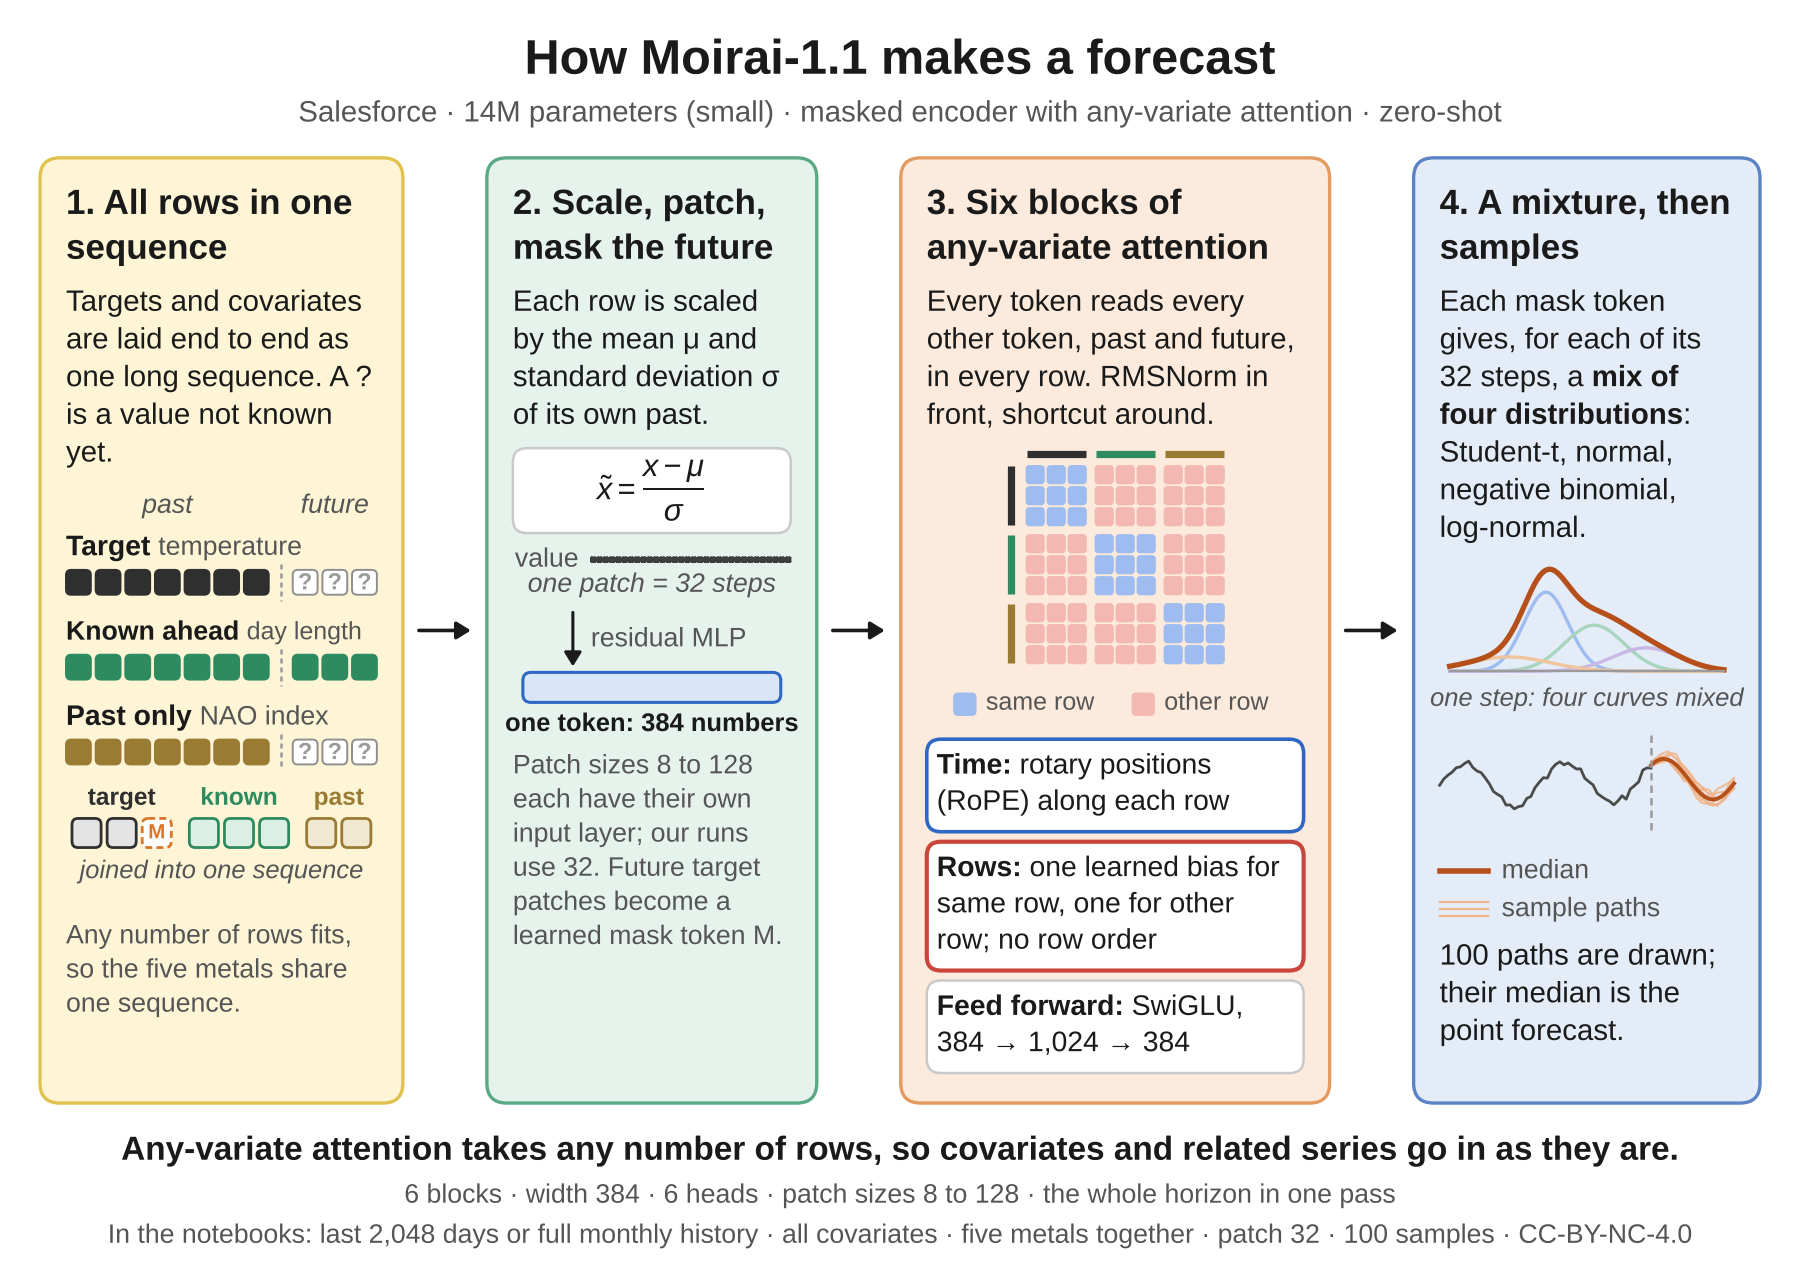

In [4]:
fig = figure("moirai11", path=FIG / "moirai11.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

**Instance normalisation** puts every series on the same scale, using the mean $\mu$ and standard deviation $\sigma$ of its own context (in the causal versions, of the values seen so far):

$$\tilde{x}_ t=\frac{x_t-\mu}{\sigma}$$

The forecast is mapped back to the original units with $x=\mu+\sigma\tilde{x}$.

**Patching** cuts the series into windows of $P$ steps, and each window becomes one token:

$$p_i=(\tilde{x}_ {(i-1)P+1},\dots,\tilde{x}_ {iP})$$

A context of $T$ steps then gives $T/P$ tokens, so attention costs $(T/P)^2$ instead of $T^2$.

The **mixture distribution** head outputs weights $w_c$ and parameters for several distributions $p_c$; their weighted sum is the forecast density:

$$p(y)=\sum_{c}w_c\thinspace p_c(y)$$

Sampling from it gives forecast paths.

**RMSNorm** divides each token vector $h$ by its root mean square and multiplies the result by a learned gain $g$:

$$\frac{h}{\sqrt{\frac{1}{d}\sum_j h_j^2+\epsilon}}\odot g$$

Here $d$ is the width of the vector and $\epsilon$ a small constant that avoids dividing by zero. The normalisation keeps the size of the activations stable through many layers.

**Any-variate attention** scores the query at time $i$ of variate $m$ against the key at time $j$ of variate $n$ as

$$q_{i,m}^{\top}R_{i-j}\thinspace k_{j,n}+u_{mn}$$

The rotary matrix $R_{i-j}$ (RoPE) encodes the distance in time, and the learned bias $u_{mn}$, which is $u_1$ when $m=n$ and $u_2$ otherwise, says whether the two tokens belong to the same variate or not. The variates are told apart without putting them in any order. A softmax over the keys turns the scores into weights (in Moirai-MoE, only over earlier time steps).

The **SwiGLU feed-forward network** passes one projection of the token through SiLU and uses it to gate a second projection, element by element ($\odot$), before projecting back:

$$W_2\left(\mathrm{SiLU}(W_1h)\odot W_3h\right)$$

It trains better than a plain ReLU network of the same size.

#### What it costs to run

Full attention over V · N tokens costs O((V · N)² · d): quadratic in the number of series as well as in time. The loaded network has 13.8M parameters.

#### Covariates

Without fine-tuning, Moirai-1.1 (small) can forecast several target series jointly and read both past-only and known-future covariates. All series are flattened into one sequence, and a learned bias in the attention says whether two tokens belong to the same series.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| masked encoder, multi patch-size input/output projections | Woo et al. 2024, Sec. 3.1.1 |
| any-variate attention: RoPE + binary attention bias | Sec. 3.1.2, Eq. 2-3 |
| pre-norm RMSNorm, QK-norm, SwiGLU, no biases; learnable [mask] embedding | Sec. 3.1 and Fig. 2 |
| mixture: Student-t, negative binomial, log-normal, low-variance normal | Sec. 3.1.3 |
| 6 layers, d_model 384, 6 heads, patch sizes 8-128 | config.json; module tree |

#### The code

This chapter's adapter for Moirai-1.1 (small) is the class `Moirai11` in [`src/ch03_zeroshot/models/moirai.py`](src/ch03_zeroshot/models/moirai.py) (line 120): it loads the checkpoint [`Salesforce/moirai-1.1-R-small`](https://huggingface.co/Salesforce/moirai-1.1-R-small), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `uni2ts` 2.0.0 library ([PyPI page](https://pypi.org/project/uni2ts/2.0.0/)). The figure above is drawn by [`architectures.py`](src/ch03_zeroshot/architectures.py).

In [5]:
forecast("moirai11")

Moirai-1.1 (Salesforce/moirai-1.1-R-small): 13.8M parameters, loaded in 12.9 s


,status,seconds,covariates read,notes
dataset,,,,
D1,ran,0.5,none,
D2,ran,4.2,"fourier_sin_1, fourier_cos_1, fourier_sin_2, fourier_cos_2, daylength_h, wav_d1_2, wav_d3_4, wav_d5_6, wav_d7_8, wav_s8, nao, ao",
D3,ran,0.4,none,
D4,ran,0.7,"global_activity, usd, real_rate_10y",


#### Which covariates hurt Moirai?

Moirai flattens every series, the target and the covariates alike, into one sequence of tokens and attends over all
of it (any-variate attention). Section 3 shows that on D2 this costs Moirai-1.1 and Moirai-MoE accuracy, and more so
at longer horizons. The cell below forecasts five 90-day windows with one group of D2's covariates at a time (about
a minute on a CPU). They are validation windows that end at the earliest test origin, so the question is asked with
past data only.

In [6]:
from ch03_zeroshot.runner import covariate_ablation

CALENDAR = ["fourier_sin_1", "fourier_cos_1", "fourier_sin_2", "fourier_cos_2", "daylength_h"]
BANDS = ["wav_d1_2", "wav_d3_4", "wav_d5_6", "wav_d7_8", "wav_s8"]
covariate_ablation(ROOT, "moirai11", "D2", 90, {
    "none": [], "calendar terms (known future)": CALENDAR, "wavelet bands (past only)": BANDS,
    "NAO and AO (past only)": ["nao", "ao"], "all twelve": CALENDAR + BANDS + ["nao", "ao"]})

,number,MAE,mean forecast,mean actual
covariates,,,,
none,0,2.042,11.27,11.34
calendar terms (known future),5,4.940,7.47,11.34
wavelet bands (past only),5,4.503,8.62,11.34
NAO and AO (past only),2,3.690,10.36,11.34
all twelve,12,4.721,7.94,11.34


Every group makes the 90-day forecast worse, and the deterministic calendar terms, which carry exactly the yearly
cycle the target follows, do the most damage: the MAE rises from about 2.0 to 4.9 °C and the mean forecast drops
from 11.3 to 7.5 °C against an actual 11.3 °C. The same pattern appears in the test windows (Section 3), so it is a
property of the model, not of one period. Moirai does not use the calendar terms as "the season ahead"; in its
attention they are simply more series to model together, and here they pull the forecast towards a cold bias. (The
test shows the effect, not its mechanism.) Chronos-2 and TimesFM-3 (Notebook 05a), given exactly the same inputs,
change by about 1% at 90 days. How a model reads covariates matters more than whether it accepts them.

## 2.2 · Moirai-MoE (small) (Salesforce)

Moirai-MoE replaces Moirai's separate patch layers for each frequency with a single patch size, and lets a sparse mixture of experts specialise on different token patterns instead. It is decoder-only (each patch predicts the next), and its router is built from k-means centroids of the token representations of a pre-trained Moirai.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

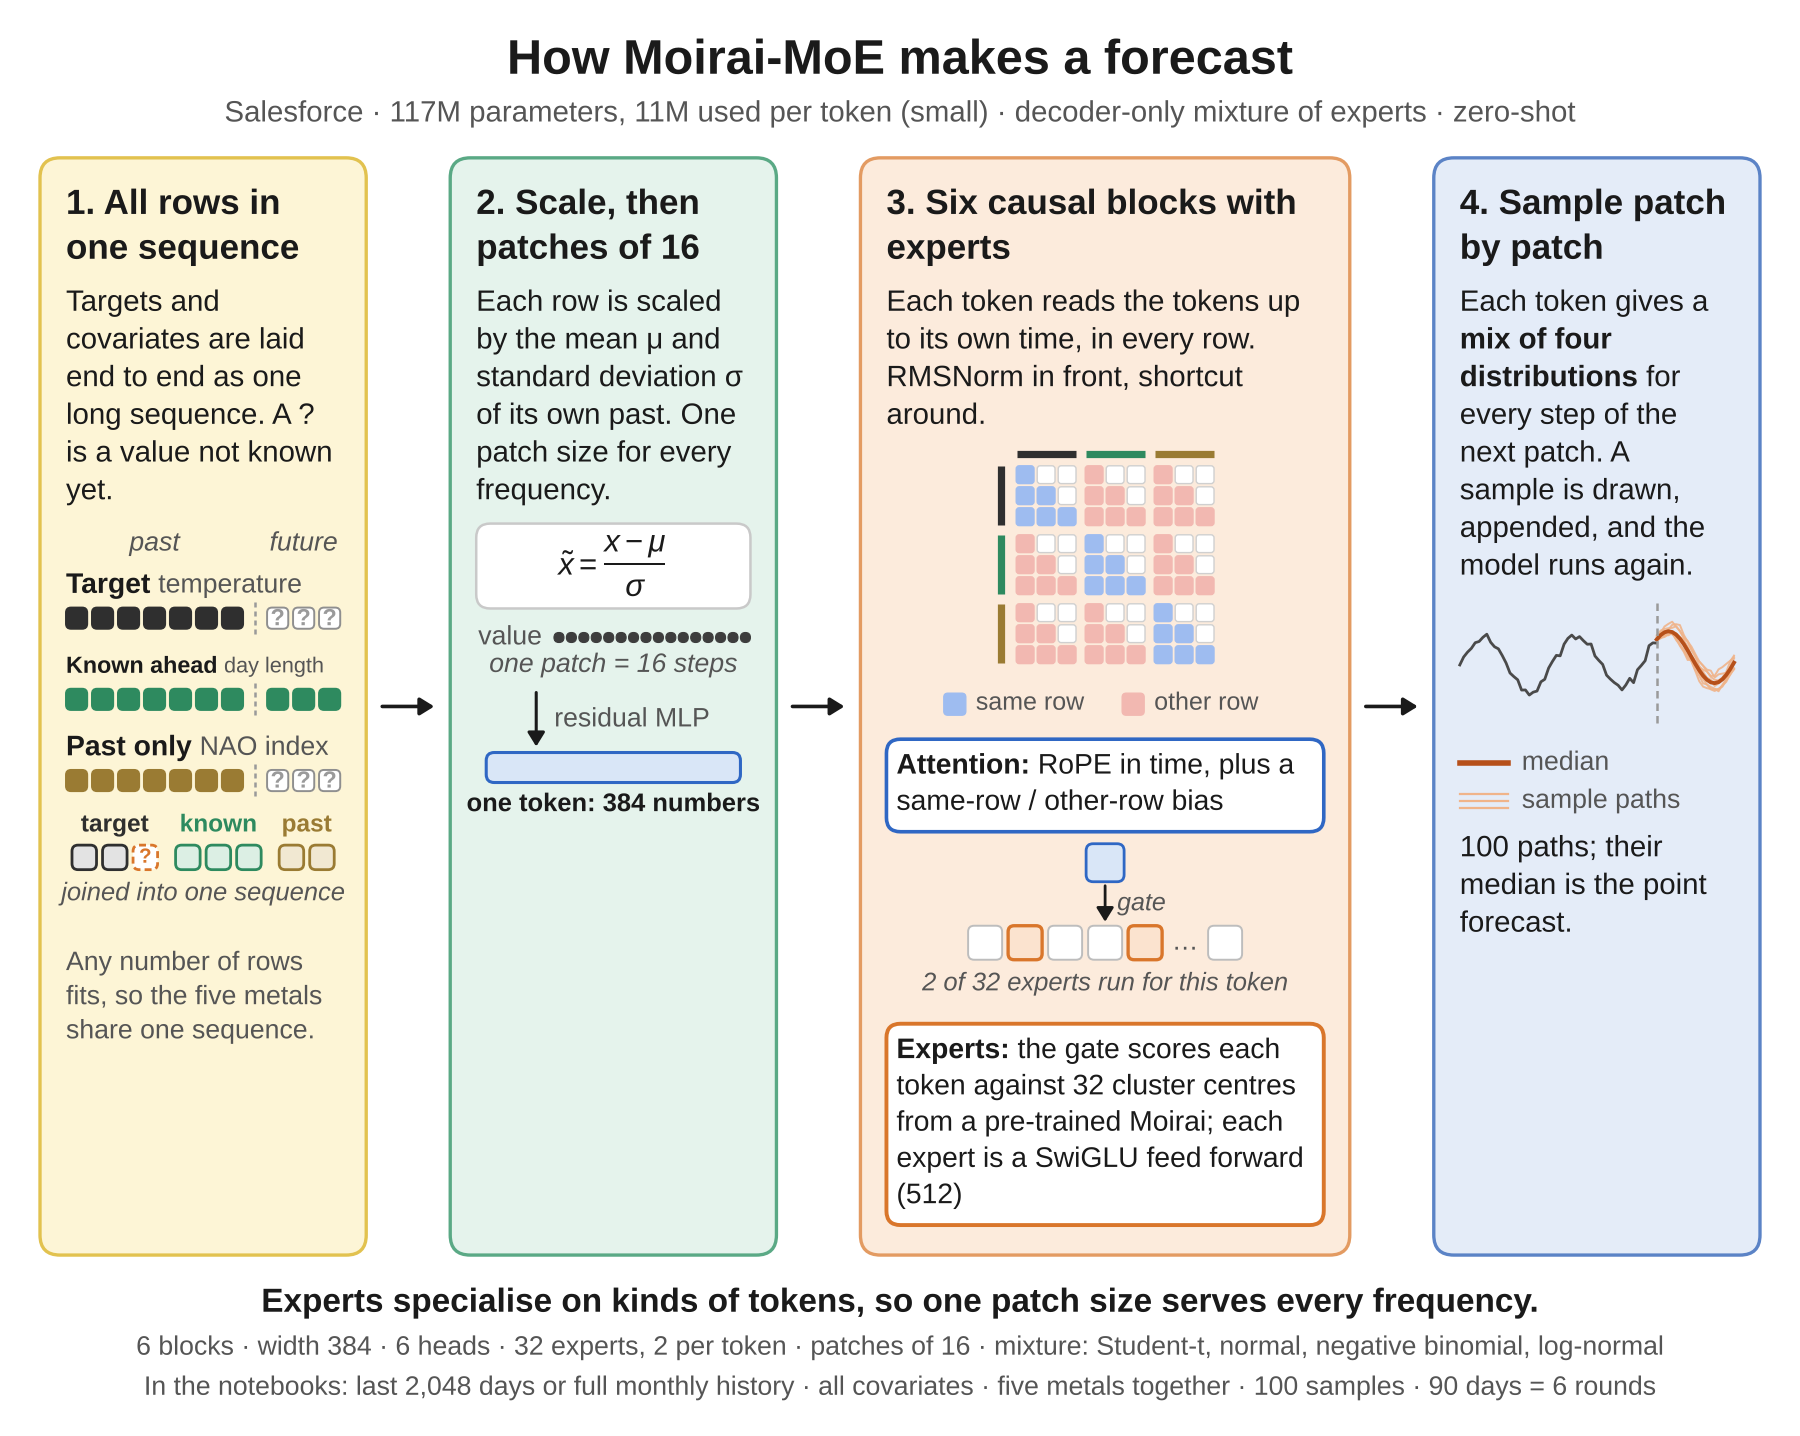

In [7]:
fig = figure("moirai-moe", path=FIG / "moirai-moe.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

**Instance normalisation** puts every series on the same scale, using the mean $\mu$ and standard deviation $\sigma$ of its own context (in the causal versions, of the values seen so far):

$$\tilde{x}_ t=\frac{x_t-\mu}{\sigma}$$

The forecast is mapped back to the original units with $x=\mu+\sigma\tilde{x}$.

**Patching** cuts the series into windows of $P$ steps, and each window becomes one token:

$$p_i=(\tilde{x}_ {(i-1)P+1},\dots,\tilde{x}_ {iP})$$

A context of $T$ steps then gives $T/P$ tokens, so attention costs $(T/P)^2$ instead of $T^2$.

The **mixture distribution** head outputs weights $w_c$ and parameters for several distributions $p_c$; their weighted sum is the forecast density:

$$p(y)=\sum_{c}w_c\thinspace p_c(y)$$

Sampling from it gives forecast paths.

**RMSNorm** divides each token vector $h$ by its root mean square and multiplies the result by a learned gain $g$:

$$\frac{h}{\sqrt{\frac{1}{d}\sum_j h_j^2+\epsilon}}\odot g$$

Here $d$ is the width of the vector and $\epsilon$ a small constant that avoids dividing by zero. The normalisation keeps the size of the activations stable through many layers.

**Any-variate attention** scores the query at time $i$ of variate $m$ against the key at time $j$ of variate $n$ as

$$q_{i,m}^{\top}R_{i-j}\thinspace k_{j,n}+u_{mn}$$

The rotary matrix $R_{i-j}$ (RoPE) encodes the distance in time, and the learned bias $u_{mn}$, which is $u_1$ when $m=n$ and $u_2$ otherwise, says whether the two tokens belong to the same variate or not. The variates are told apart without putting them in any order. A softmax over the keys turns the scores into weights (in Moirai-MoE, only over earlier time steps).

In a **mixture of experts**, a router scores the experts $E_k$ for each token, keeps the top few, the set $S(h)$, and adds their outputs weighted by its gates $g_k$:

$$\sum_{k\in S(h)}g_k(h)\thinspace E_k(h)$$

Only those experts run, so the active model is much smaller than the total.

#### What it costs to run

Attention costs O((V · N)² · d). Each token runs only 2 of the 32 expert feed-forward networks, so the compute per token matches a dense model of about 11M parameters. The loaded network has 117.0M parameters.

#### Covariates

Without fine-tuning, Moirai-MoE (small) can forecast several target series jointly and read both past-only and known-future covariates. It packs the series and biases the attention in the same way as Moirai-1.1.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| decoder-only, single projection, sparse MoE replacing FFN | Liu, Liu et al. 2024, Sec. 3 |
| token-cluster gating (k-means centroids of pretrained Moirai) | Sec. 3.2.1, Eq. 6 |
| top-2 of 32 experts; small: 6 layers, d 384, d_ff 512, 11M active / 117M total | Sec. 4.1, Table 1 |
| normaliser statistics from the first part of the sequence in training (Sec. 3.1); at inference the whole observed context | uni2ts moirai_moe/module.py PackedStdScaler |
| residual MLP projection | Sec. 3.1 |
| patch size 16; 32 GatedLinearUnit experts | config.json; module tree |

#### The code

This chapter's adapter for Moirai-MoE (small) is the class `MoiraiMoE` in [`src/ch03_zeroshot/models/moirai.py`](src/ch03_zeroshot/models/moirai.py) (line 140): it loads the checkpoint [`Salesforce/moirai-moe-1.0-R-small`](https://huggingface.co/Salesforce/moirai-moe-1.0-R-small), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `uni2ts` 2.0.0 library ([PyPI page](https://pypi.org/project/uni2ts/2.0.0/)). The figure above is drawn by [`architectures.py`](src/ch03_zeroshot/architectures.py).

In [8]:
forecast("moirai-moe")

Moirai-MoE (Salesforce/moirai-moe-1.0-R-small): 117.0M parameters, loaded in 19.3 s


,status,seconds,covariates read,notes
dataset,,,,
D1,ran,0.2,none,
D2,ran,0.9,"fourier_sin_1, fourier_cos_1, fourier_sin_2, fourier_cos_2, daylength_h, wav_d1_2, wav_d3_4, wav_d5_6, wav_d7_8, wav_s8, nao, ao","CPU: 13 variates, context shortened from 2048 to 768 steps (token cap 640)"
D3,ran,0.2,none,
D4,ran,0.3,"global_activity, usd, real_rate_10y",


## 2.3 · Moirai-2.0 (small) (Salesforce)

Moirai 2.0 simplifies Moirai: a decoder-only transformer with one patch size, trained with a quantile (pinball) loss instead of a mixture likelihood, that predicts four patches at each step. It is 30 times smaller than Moirai-1.0-Large and univariate.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

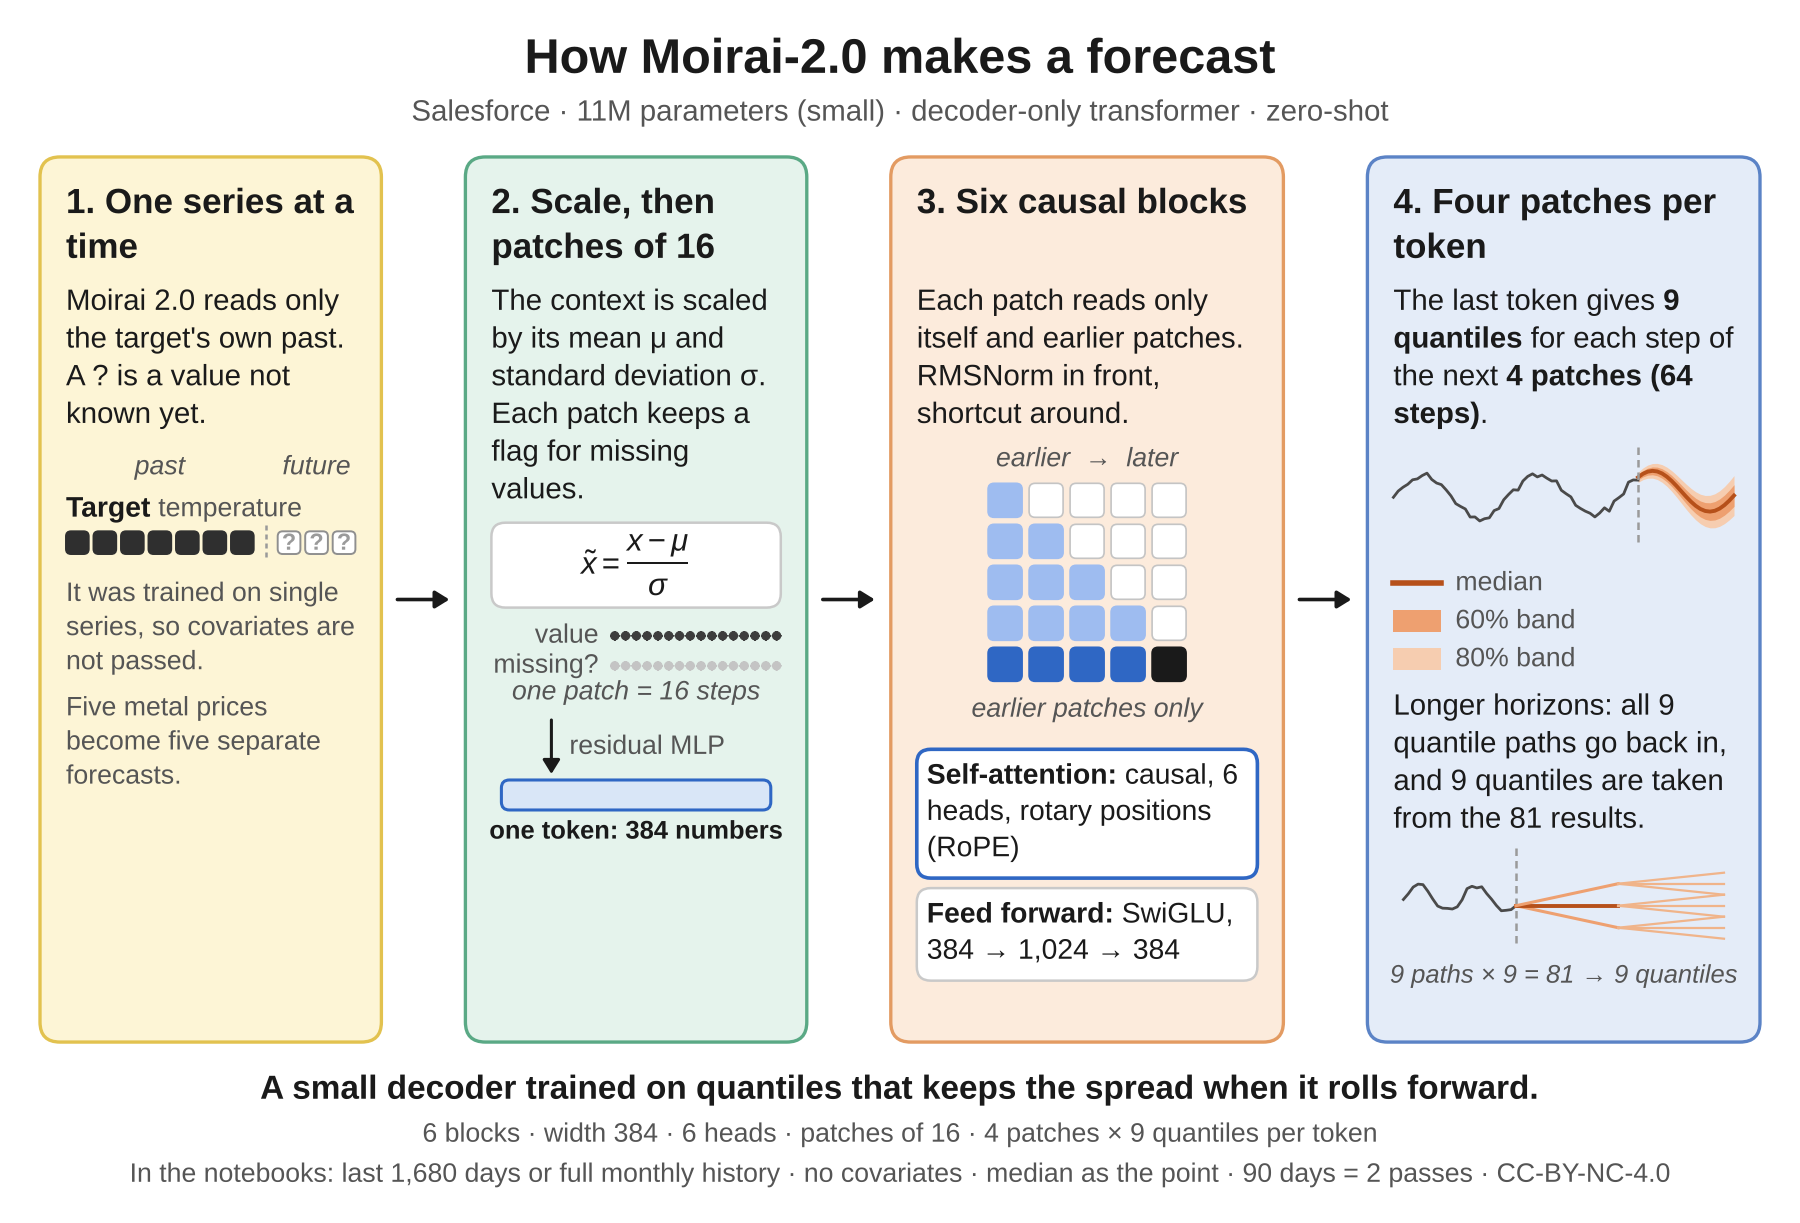

In [9]:
fig = figure("moirai2", path=FIG / "moirai2.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

**Instance normalisation** puts every series on the same scale, using the mean $\mu$ and standard deviation $\sigma$ of its own context (in the causal versions, of the values seen so far):

$$\tilde{x}_ t=\frac{x_t-\mu}{\sigma}$$

The forecast is mapped back to the original units with $x=\mu+\sigma\tilde{x}$.

**Patching** cuts the series into windows of $P$ steps, and each window becomes one token:

$$p_i=(\tilde{x}_ {(i-1)P+1},\dots,\tilde{x}_ {iP})$$

A context of $T$ steps then gives $T/P$ tokens, so attention costs $(T/P)^2$ instead of $T^2$.

The **quantile head** has one output per quantile level $\tau$. Training minimises the pinball loss $\rho_\tau$ of the error $u=y-\hat{q}_ \tau$:

$$\rho_\tau(u)=\max(\tau u,\thinspace(\tau-1)u)$$

Minimising this loss makes each output the $\tau$-quantile of the forecast distribution. The median ($\tau=0.5$) is the point forecast scored in this chapter.

**RMSNorm** divides each token vector $h$ by its root mean square and multiplies the result by a learned gain $g$:

$$\frac{h}{\sqrt{\frac{1}{d}\sum_j h_j^2+\epsilon}}\odot g$$

Here $d$ is the width of the vector and $\epsilon$ a small constant that avoids dividing by zero. The normalisation keeps the size of the activations stable through many layers.

**Masked self-attention** compares each token's query $Q$ with the keys $K$, turns the scores into weights with a softmax, and uses the weights to mix the values $V$:

$$\mathrm{softmax}\left(\frac{QK^{\top}}{\sqrt{d_k}}+M\right)V$$

The mask $M$ is $-\infty$ wherever a token may not read another: a later time step in causal attention, or an excluded pair in variate attention (covariates that may not read targets, or rows that belong to different series). Dividing by $\sqrt{d_k}$, the square root of the key width, keeps the scores in a range where the softmax does not saturate.

The **SwiGLU feed-forward network** passes one projection of the token through SiLU and uses it to gate a second projection, element by element ($\odot$), before projecting back:

$$W_2\left(\mathrm{SiLU}(W_1h)\odot W_3h\right)$$

It trains better than a plain ReLU network of the same size.

#### What it costs to run

O(L · N² · d) for N = T/16, with one decoding round per 64 steps. The loaded network has 11.4M parameters.

#### Covariates

Without fine-tuning, Moirai-2.0 (small) reads no covariates: it forecasts each series on its own. Its authors dropped the multivariate and covariate support of the earlier Moirai models.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| decoder-only, single patch, quantile loss, multi-token prediction | Liu, Aksu et al. 2025, Sec. 3.1 |
| patch + missing indicator, residual block from 2p inputs to width d | Sec. 3.1 Eq. 1 |
| autoregressive multi-quantile decoding (expand, collapse) | Sec. 3.2, Algorithm 1 |
| univariate; covariates dropped | Sec. 3.1 and 6 |
| 6 layers, d 384, d_ff 1024, patch 16, 4 predict tokens, 9 quantiles; head 384 → 576 | config.json; module tree |

#### The code

This chapter's adapter for Moirai-2.0 (small) is the class `Moirai2` in [`src/ch03_zeroshot/models/moirai.py`](src/ch03_zeroshot/models/moirai.py) (line 214): it loads the checkpoint [`Salesforce/moirai-2.0-R-small`](https://huggingface.co/Salesforce/moirai-2.0-R-small), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `uni2ts` 2.0.0 library ([PyPI page](https://pypi.org/project/uni2ts/2.0.0/)). The figure above is drawn by [`architectures.py`](src/ch03_zeroshot/architectures.py).

In [10]:
forecast("moirai2")

Moirai-2.0 (Salesforce/moirai-2.0-R-small): 11.4M parameters, loaded in 1.6 s


,status,seconds,covariates read,notes
dataset,,,,
D1,ran,0.0,none,
D2,D1 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D1's"
D3,ran,0.1,none,
D4,D3 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D3's"


## 3 · Results of the full runs

The tables below read the stored forecasts of every horizon and rolling window (or your own, after
`FULL_RUN = True`). The helper functions behind them (scores, tables, plots and gain tables) are in
[`src/ch03_zeroshot/report.py`](src/ch03_zeroshot/report.py), and the metrics in
[`metrics.py`](src/ch03_zeroshot/metrics.py).

Each model's point forecast is its median, or its mean for the models that output one. Two errors score it. The
**MASE** (mean absolute scaled error) divides the mean absolute error of the forecast by the mean absolute error
that a naive rule makes on the history up to the forecast origin $T$:

$$\mathrm{MASE} = \frac{\frac{1}{H}\sum_{h=1}^{H}\left|y_{T+h}-\hat y_{T+h}\right|}{\frac{1}{T-\ell}\sum_{t=\ell+1}^{T}\left|y_t-y_{t-\ell}\right|}.$$

The naive rule repeats the value from $\ell$ steps earlier: the same day last year for temperature ($\ell = 365$), and the last value for metal prices ($\ell = 1$).
A MASE below 1 means that the model's errors were smaller than the errors the naive rule made on the history. The
**RMSE**, the root mean squared error, squares the errors before averaging, so it punishes large misses more.

Notebook 11 adds more metrics and compares every model of the chapter. This section looks
only at the models of this notebook, next to the naive and seasonal naive forecasts.

#### MASE by dataset and horizon

The best value in each row is in bold.

On D2 and D4 a model that cannot read the covariates gets exactly its D1 or D3 input, so its rows there repeat its D1 or D3 rows (the naive and seasonal naive rules read no covariates at all).

In [11]:
fc = load_forecasts(ROOT, MODELS + ["naive", "snaive"], DATASETS)
agg = aggregate(scores_cached(ROOT, MODELS + ["naive", "snaive"], DATASETS))
show_horizon_table(agg, "MASE", MODELS + ["naive", "snaive"], NAMES)

#### RMSE by dataset and horizon

The same table for the root mean squared error. Squaring the errors before averaging makes the RMSE weigh large
misses more than the MASE does, so a model that is usually close but sometimes far off looks worse here. To average over the five metals, whose prices differ by a factor of about ten,
the mean squared error (MSE) of the forecast is divided by the mean squared error of the naive rule on the history,
and the square root of the ratio is taken. The result is the root mean squared scaled error (RMSSE), whose weighted
form was the accuracy metric of the M5 forecasting competition:

$$\mathrm{MSE} = \frac{1}{H}\sum_{h=1}^{H}\left(y_{T+h}-\hat y_{T+h}\right)^2, \qquad \mathrm{MSE}_ {\text{naive}} = \frac{1}{T-\ell}\sum_{t=\ell+1}^{T}\left(y_t-y_{t-\ell}\right)^2,$$

$$\mathrm{RMSSE} = \sqrt{\mathrm{MSE} / \mathrm{MSE}_ {\text{naive}}}.$$

Below 1 again means smaller errors than the naive rule made on the history. Notebook 11 shows
the RMSE in the units of the data for every series.

In [12]:
show_horizon_table(agg, "RMSSE", MODELS + ["naive", "snaive"], NAMES)

#### Actual values against the forecasts

There is one figure per dataset, with one row of panels per series (all five metals on D3 and D4) and one panel per horizon. Each
panel shows the recent history (grey), what actually happened (black) and the point forecast of each model, all from
the same test window. Window 1 is the most recent one and ends at the last observation, so the longer horizons
start further back in time. To show fewer series, change `SERIES` (for example to `"copper"` for one metal); to look at an older
window, change `WINDOW` (daily data has 5 rolling windows, monthly data 3, and 1 at 24 months). On D2 and D4 only the models that read the covariates are drawn: the others'
forecasts are identical to their D1 or D3 forecasts.

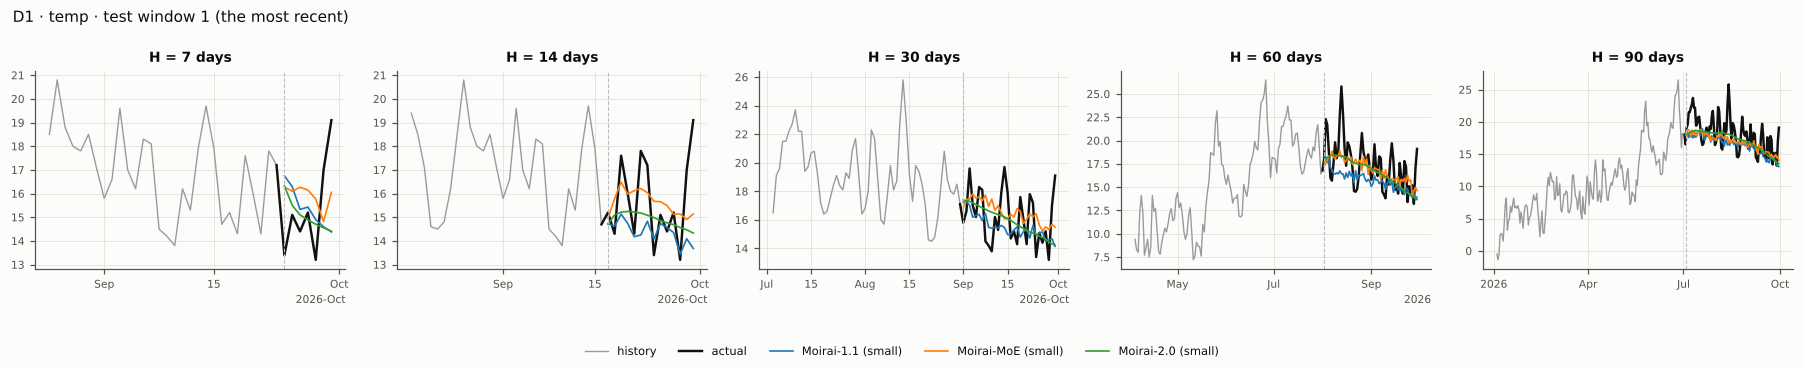

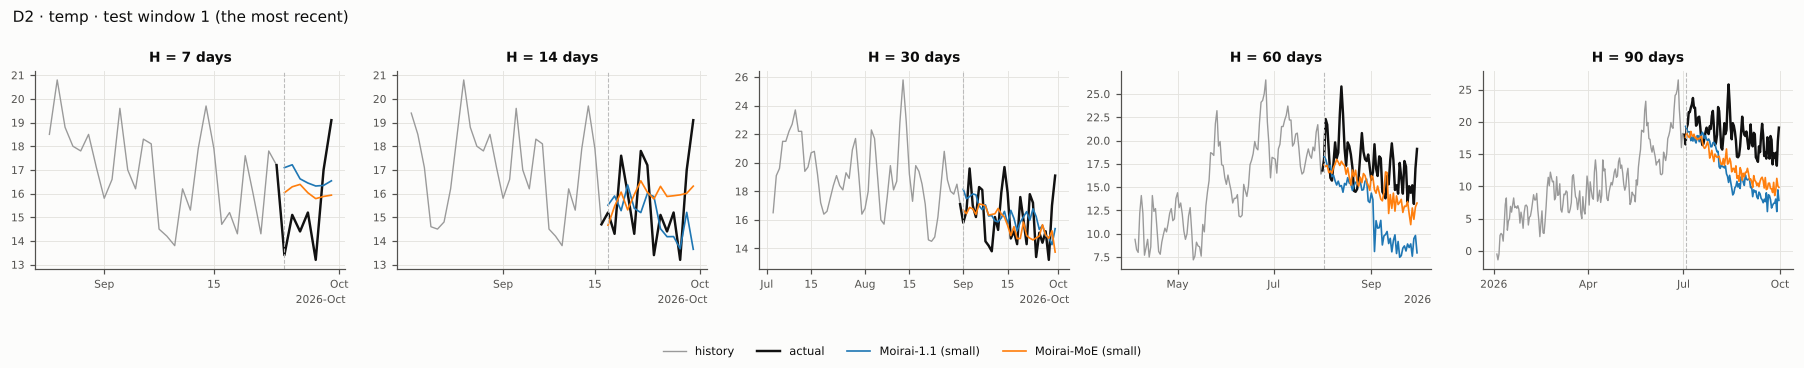

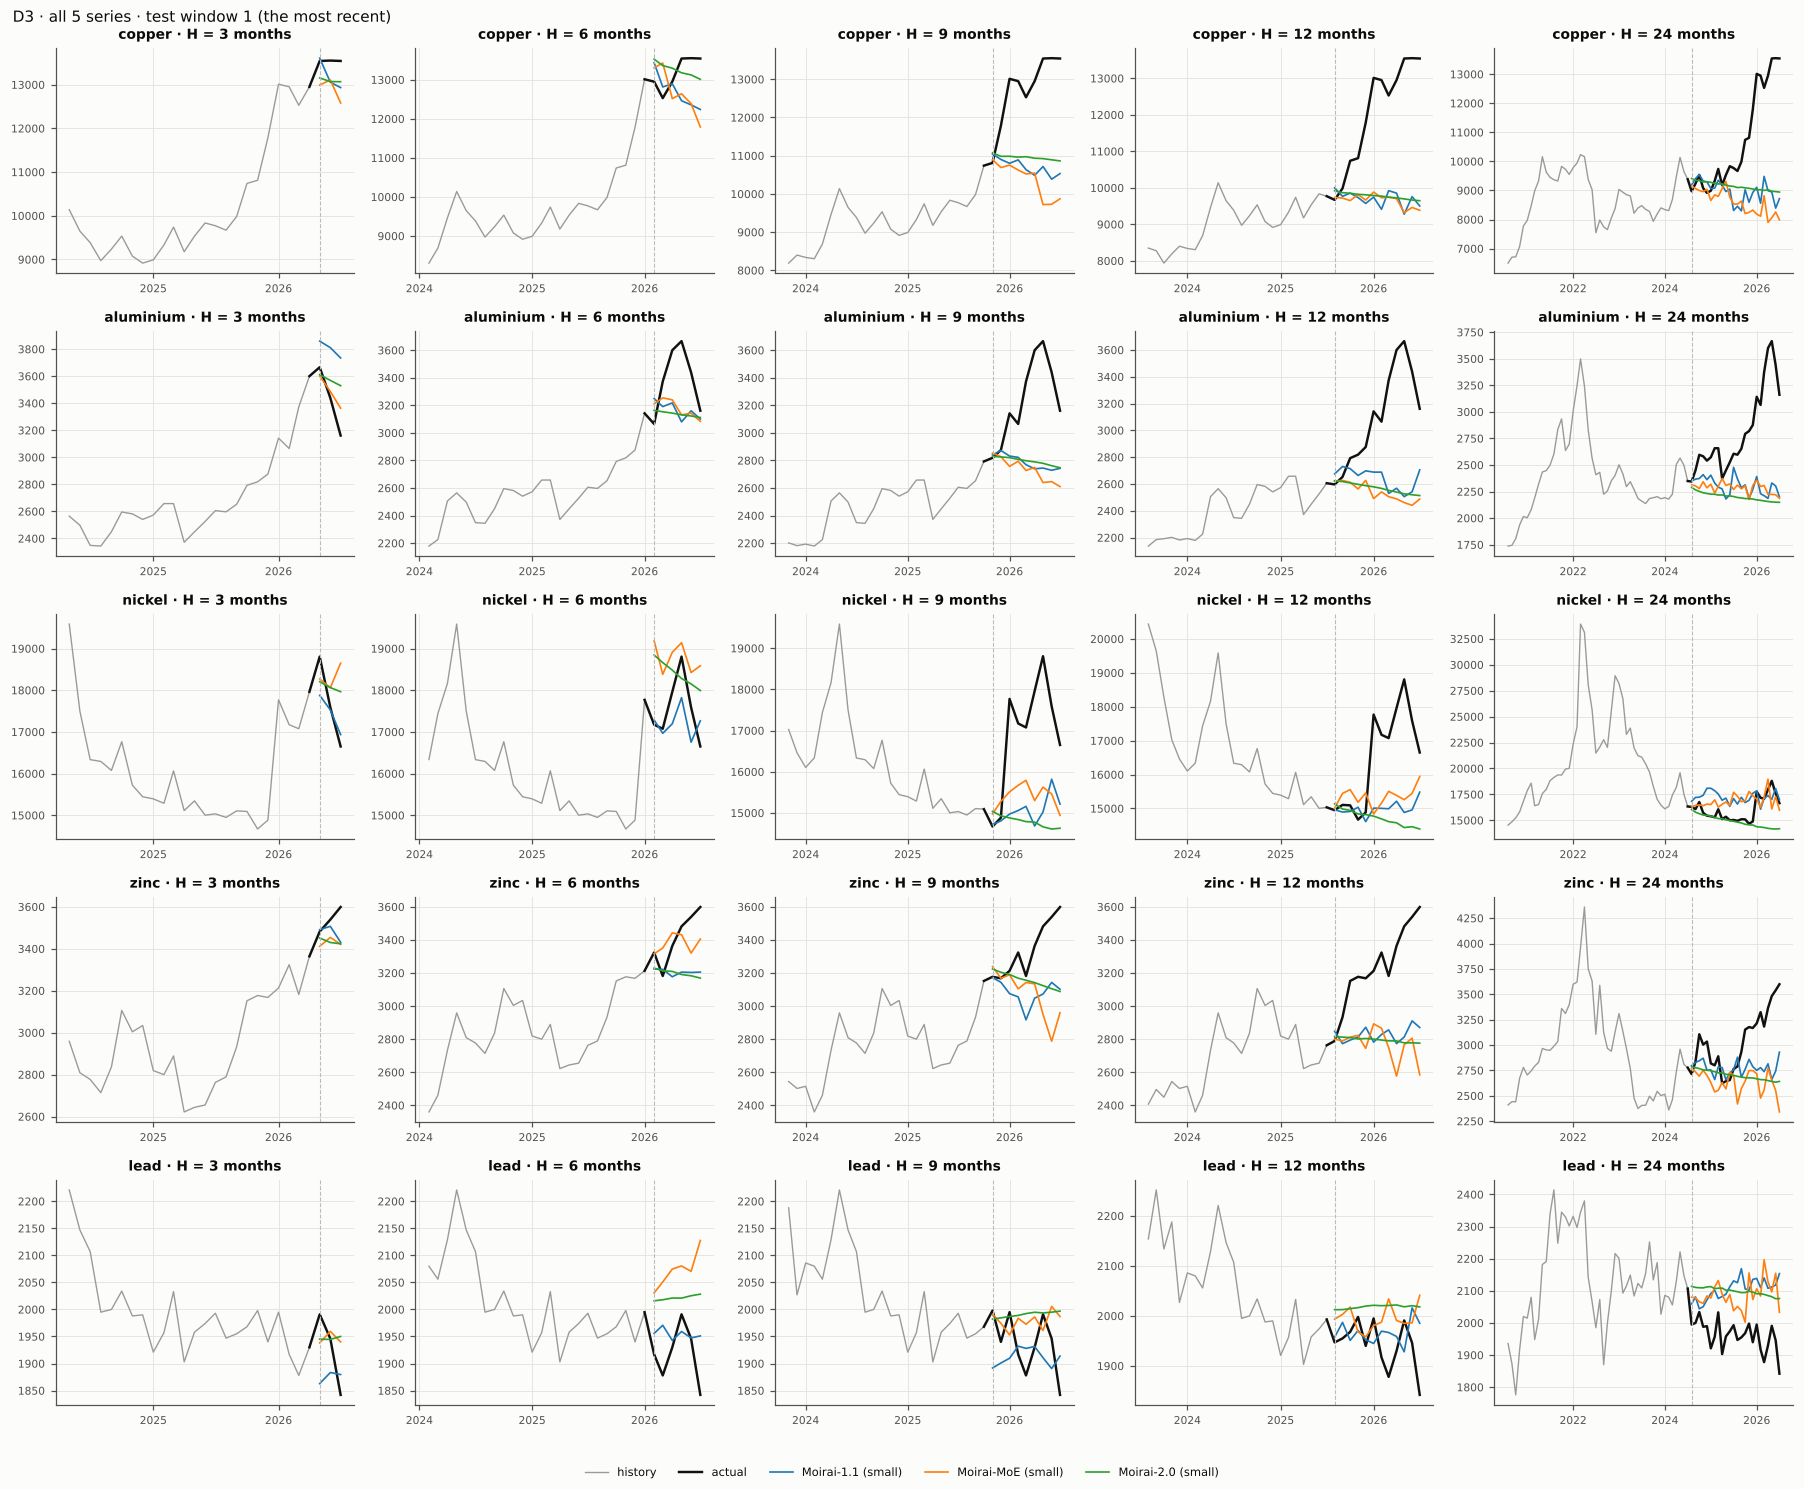

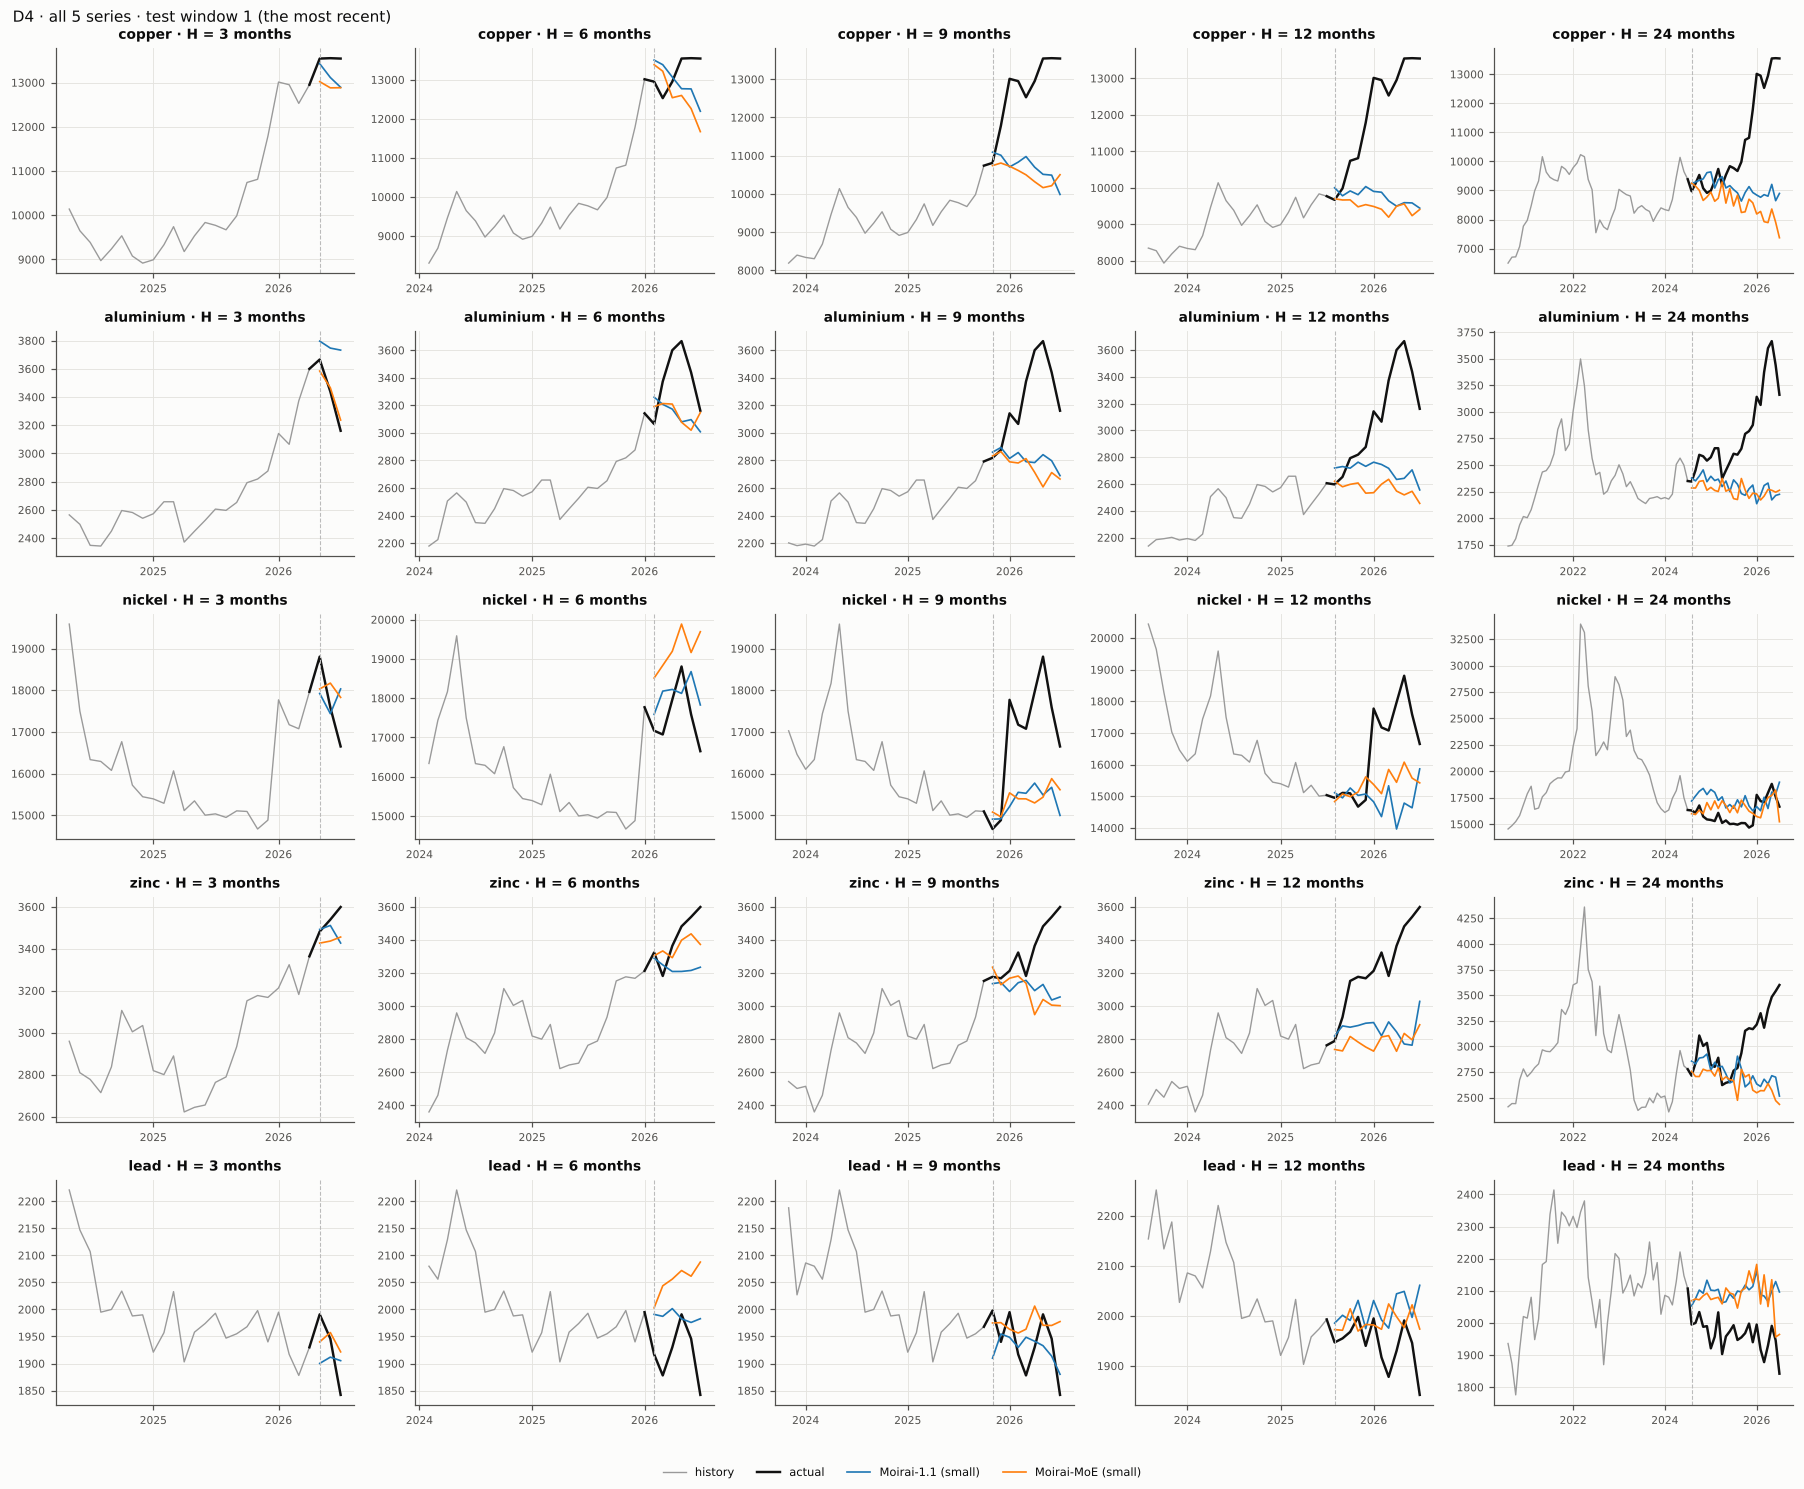

In [13]:
# the series to show: "all", one name or a list of names;
# D3 and D4 hold copper, aluminium, nickel, zinc and lead
SERIES = {"D1": "temp", "D2": "temp", "D3": "all", "D4": "all"}
WINDOW = 1  # 1 = the most recent test window
frames = {d: load_frame(ROOT, d) for d in DATASETS}
figs = forecast_gallery(fc, frames, SERIES, MODELS, NAMES, window=WINDOW)

#### The forecasts in numbers

For each dataset, the table shows the actual values and every model's point forecast at one horizon of the same test window, with the naive and seasonal naive rules as baselines.
`SERIES` and `WINDOW` work as in the plots above, so there is one table per series; change `HORIZON` to see another
horizon. In each row the forecast closest to the actual value is in bold. The grey rows underneath summarise the
window: the MAE, the RMSE and the mean error ME = mean(actual − forecast), which is positive when the forecasts were
too low. The best value of each is in bold. One window is a small sample, so these numbers can rank the models
differently from the averages over all windows in the tables above. Every horizon of the window is saved as a CSV
file in `results/tables/forecast_vs_actual/`.

In [14]:
HORIZON = {"D1": 14, "D2": 14, "D3": 6, "D4": 6}   # D1, D2: 7, 14, 30, 60 or 90 days; D3, D4: 3, 6, 9, 12 or 24 months
show_forecast_tables(fc, SERIES, HORIZON, MODELS + ["naive", "snaive"], NAMES, window=WINDOW, datasets=list(frames),
                     save=RESULTS / "tables" / "forecast_vs_actual" / "06.csv")

**D1 · temp · H = 14 days · test window 1** (2026-09-17 to 2026-09-30)

,actual,Moirai-1.1 (small),Moirai-MoE (small),Moirai-2.0 (small),Naive (RW),Seasonal naive
2026-09-17,15.20,14.73,14.96,14.71,14.70,15.10
2026-09-18,14.30,14.62,15.78,15.10,14.70,17.70
2026-09-19,17.60,15.13,16.48,15.21,14.70,18.80
2026-09-20,16.00,14.74,15.98,15.25,14.70,15.90
2026-09-21,14.30,14.18,16.12,15.22,14.70,10.80
2026-09-22,17.80,14.25,16.21,15.18,14.70,9.30
2026-09-23,17.20,14.83,16.04,15.09,14.70,9.80
2026-09-24,13.40,14.09,15.67,14.99,14.70,12.10
2026-09-25,15.10,14.73,15.66,14.85,14.70,11.60
2026-09-26,14.40,14.56,15.50,14.77,14.70,10.80


**D2 · temp · H = 14 days · test window 1** (2026-09-17 to 2026-09-30)

,actual,Moirai-1.1 (small),Moirai-MoE (small),Naive (RW),Seasonal naive
2026-09-17,15.20,15.51,14.66,14.70,15.10
2026-09-18,14.30,15.90,15.46,14.70,17.70
2026-09-19,17.60,15.28,16.06,14.70,18.80
2026-09-20,16.00,16.36,15.31,14.70,15.90
2026-09-21,14.30,15.38,15.95,14.70,10.80
2026-09-22,17.80,15.20,16.54,14.70,9.30
2026-09-23,17.20,16.00,16.06,14.70,9.80
2026-09-24,13.40,15.87,15.77,14.70,12.10
2026-09-25,15.10,14.52,16.31,14.70,11.60
2026-09-26,14.40,14.18,15.88,14.70,10.80


**D3 · copper · H = 6 months · test window 1** (2026-02-01 to 2026-07-01)

,actual,Moirai-1.1 (small),Moirai-MoE (small),Moirai-2.0 (small),Naive (RW),Seasonal naive
2026-02-01,"12,951","13,435","13,307","13,526","13,012","9,331"
2026-03-01,"12,529","12,815","13,427","13,362","13,012","9,740"
2026-04-01,"12,951","12,897","12,517","13,296","13,012","9,177"
2026-05-01,"13,543","12,462","12,640","13,177","13,012","9,533"
2026-06-01,"13,552","12,357","12,389","13,124","13,012","9,835"
2026-07-01,"13,543","12,239","11,790","13,011","13,012","9,771"
MAE,,734,918,513,368,"3,614"
RMSE,,877,"1,030",539,427,"3,634"
ME (actual - forecast),,477,500,-71,166,"3,614"


... (15 outputs left out)

,actual,Moirai-1.1 (small),Moirai-MoE (small),Naive (RW),Seasonal naive
2026-02-01,"3,324","3,290","3,305","3,213","2,800"
2026-03-01,"3,182","3,249","3,333","3,213","2,889"
2026-04-01,"3,364","3,209","3,293","3,213","2,622"
2026-05-01,"3,482","3,209","3,398","3,213","2,644"
2026-06-01,"3,539","3,216","3,437","3,213","2,655"
2026-07-01,"3,599","3,235","3,373","3,213","2,763"
MAE,,203,109,212,686
RMSE,,238,127,246,718
ME (actual - forecast),,180,58,202,686


**D4 · lead · H = 6 months · test window 1** (2026-02-01 to 2026-07-01)

,actual,Moirai-1.1 (small),Moirai-MoE (small),Naive (RW),Seasonal naive
2026-02-01,"1,917","1,991","2,003","1,995","1,957"
2026-03-01,"1,878","1,987","2,044","1,995","2,033"
2026-04-01,"1,930","2,002","2,056","1,995","1,903"
2026-05-01,"1,991","1,983","2,072","1,995","1,958"
2026-06-01,"1,946","1,976","2,061","1,995","1,974"
2026-07-01,"1,842","1,983","2,088","1,995","1,993"
MAE,,72,137,78,72
RMSE,,85,148,91,92
ME (actual - forecast),,-70,-137,-78,-52


Every horizon of window 1 saved to /home/user/fresh/repo/Chapter03_Zero_Shot_Forecasting/results/tables/forecast_vs_actual/06.csv


#### Do the covariates help, by MASE and by RMSE?

For every model in this notebook that reads covariates, the tables give the % change in the error when the model gets the covariates:
D2 (the twelve temperature covariates) against D1, and D4 (three drivers, past values only) against D3. Negative
(green) means the covariates helped, positive (red) that they hurt. The MASE change says whether the typical error
shrank; the RMSE change, because it squares the errors, says whether the large misses shrank. When the two
disagree, the covariates helped with one kind of error only.

Three points help in reading the tables:

- **Daily and monthly results are in separate tables.** D2 against D1 is scored at 7 to 90 days and the metals at
  3 to 24 months. In one shared table every daily row would have empty cells (NaN, "not a number") under the monthly
  horizons and every monthly row under the daily ones: there was nothing to compute there, not a failed run.
- **A model is listed only where it read covariates.** A model that cannot read a kind of covariate ignores it, so
  its D2 or D4 forecasts are identical to its D1 or D3 forecasts and there is no gain to report. For example
  TimesFM-2.5 (Notebook 05a) reads only known-future covariates: it appears on D2, whose annual harmonics and day
  length are known in advance, but not on D4, whose drivers are past-only.
- **The RMSE change is measured series by series.** For temperature it is exactly the change in RMSE; for the
  metals it is the change in the scaled RMSE (RMSSE), so that nickel, at about 16,000 dollars a tonne, does not
  outweigh lead at about 2,000. An "n/a" would mark a horizon a model did not run.

In [15]:
gains = gain_tables(agg, MODELS, NAMES)
show_gains(gains)

**Daily temperature, D2 against D1 (horizons in days)**: % change in MASE and in RMSE when the model reads the covariates

**Monthly metals, D4 against D3 (horizons in months)**: % change in MASE and in RMSE when the model reads the covariates

**MASE against RMSE**: mean change over the horizons, and at how many horizons each metric improves

#### What the runs cost

The time spent forecasting, in seconds, over all horizons and rolling windows on 4 CPU cores. A value of 0.0 means that the model reads none of that dataset's covariates, so its D1 or D3 forecasts were reused.

In [16]:
runs = run_summary(ROOT, MODELS)
cost_table(runs, DATASETS)

dataset,D1,D2,D3,D4
model,,,,
Moirai-1.1,4.5,81.6,3.2,5.2
Moirai-2.0,1.9,0.0,0.5,0.0
Moirai-MoE,307.9,2066.0,7.6,17.4


## 4 · Key insights


- **The newest and smallest Moirai is the best.** Moirai-2.0 (small, 11M weights) reaches a mean MASE of 0.673 on D1,
  level with Chronos-Bolt (0.672), ahead of Moirai-MoE (0.695, 117M weights in total) and Moirai-1.1 (0.714, 14M).
  All three beat the seasonal naive forecast (0.858) by 17% to 22%.
- **No Moirai beats the random walk on metals.** Their mean MASE on D3 is 2.95 to 3.25 against 2.76. At 3 months
  Moirai-2.0 (1.84) is level with it (1.83) and Moirai-MoE (1.88) is close; beyond 6 months all three fall behind.
- **Covariates hurt Moirai-1.1 and Moirai-MoE badly on D2.** With the twelve covariates the MASE of Moirai-1.1 rises
  by 28% at 7 days and doubles at 90 days (+105%); Moirai-MoE loses 9% at 7 days and 99% at 90 days. The test in
  section 2.1, on validation windows before the test period, isolates the cause: every covariate group hurts, the calendar terms most, and they drag the forecast
  towards a cold bias. (For Moirai-MoE the CPU token cap also shortens the context to 688-768 days on D2.)
- **By RMSE the D2 loss is a little smaller at most horizons, but just as clear.** Moirai-1.1's RMSE rises by 15% at
  7 days and 95% at 90 days (MASE: 28% and 105%), Moirai-MoE's by 12% and 87% (MASE: 9% and 99%). A smaller rise in
  RMSE than in MASE means the covariates raise the typical error more than the largest misses, which fits a forecast
  shifted as a whole towards a cold bias. On the metals the two metrics agree in 8 of 10 cells, all between -8% and +4%.
- **The metal drivers neither help nor hurt much.** D4's past-only drivers change MASE by -7% to +3%, with no
  consistent sign over the horizons.
- **Moirai-2.0 is also one of the cheapest models of the chapter.** It forecasts every window of D1 in 1.9 s.
  Moirai-MoE needs 308 s for D1 and 2,066 s for D2: after the first 16-step patch it reruns its decoder on 100 sample
  paths, so its cost grows with the horizon and the number of variates.

## References

- Moirai-1.1 (small): Woo et al. (2024), [arXiv:2402.02592](https://arxiv.org/abs/2402.02592); [model card](https://huggingface.co/Salesforce/moirai-1.1-R-small)
- Moirai-MoE (small): Liu, Liu et al. (2024), [arXiv:2410.10469](https://arxiv.org/abs/2410.10469); [model card](https://huggingface.co/Salesforce/moirai-moe-1.0-R-small)
- Moirai-2.0 (small): Liu, Aksu et al. (2025), [arXiv:2511.11698](https://arxiv.org/abs/2511.11698), Sections 3.1 and 6; [model card](https://huggingface.co/Salesforce/moirai-2.0-R-small)
- Raschka, S. (2024). *Build a Large Language Model (From Scratch)*. Manning, ISBN 978-1-63343-716-6. Code: [github.com/rasbt/LLMs-from-scratch](https://github.com/rasbt/LLMs-from-scratch)
- Hyndman, R. J., & Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting*, 22(4), 679-688 (MASE). [doi:10.1016/j.ijforecast.2006.03.001](https://doi.org/10.1016/j.ijforecast.2006.03.001)